# APML Challenge 2026-1: Forecasting house prices in California

**Semillero APML (Automation of Processes in Machine Learning), Universidad EIA**

**Objective:** predict the median house value of the districts of California from their characteristics.

**Dataset:** `housing.csv` (20.640 districts, 10 variables).

## Part 1. Importing the libraries and loading the data

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")

In [2]:
from pathlib import Path
import tarfile, urllib.request

def cargar_datos():
    ruta = Path("datasets/housing.tgz")
    if not ruta.is_file():
        Path("datasets").mkdir(parents=True, exist_ok=True)
        url = "https://github.com/ageron/data/raw/main/housing.tgz"
        urllib.request.urlretrieve(url, ruta)
        with tarfile.open(ruta) as t:
            t.extractall(path="datasets")
    return pd.read_csv(Path("datasets/housing/housing.csv"))

housing = cargar_datos()

## Part 2. Exploring the data

In [3]:
housing.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [4]:
housing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [5]:
housing.describe().T

,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20433.0,537.870553,421.385070,1.0000,296.0000,435.0000,647.00000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000


## Part 3. Categorical variable, visualisation and missing values

The only categorical variable is `ocean_proximity`, which has 5 values.

In [6]:
housing["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

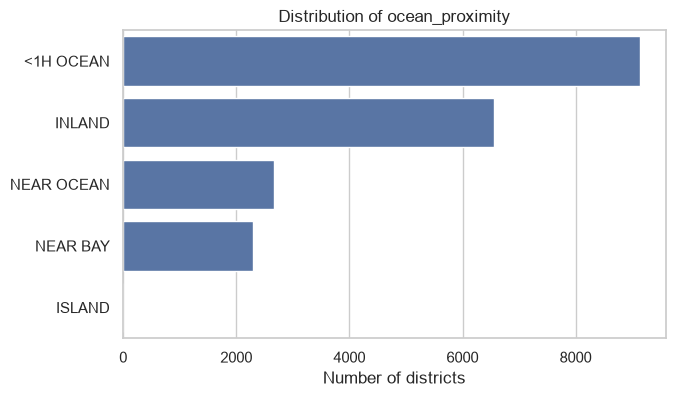

In [7]:
plt.figure(figsize=(7, 4))
orden = housing["ocean_proximity"].value_counts().index
sns.countplot(data=housing, y="ocean_proximity", order=orden, color="#4C72B0")
plt.title("Distribution of ocean_proximity")
plt.xlabel("Number of districts"); plt.ylabel("")
plt.show()

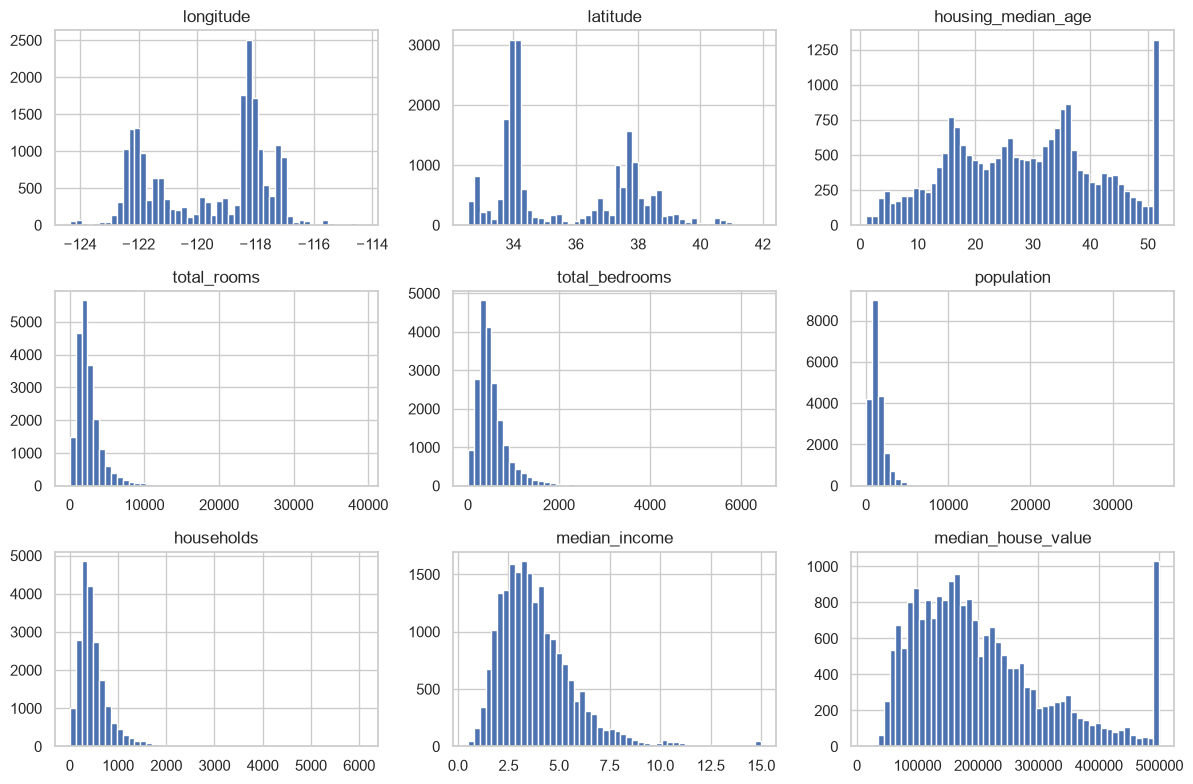

In [8]:
housing.hist(bins=50, figsize=(12, 8), color="#4C72B0", edgecolor="white")
plt.tight_layout()
plt.show()

Number of missing values by variable:

In [9]:
housing.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

## Part 4. Preparing the data

It includes: train/test split, geographic visualisation, correlations,
scatter plots, imputation of missing values, treatment of anomalies,
encoding of categorical variables, normalisation and log transformation.

### 4.1 Train and test split

We use stratified sampling by income category to keep the same
income distribution in both sets.

In [10]:
housing["income_cat"] = pd.cut(housing["median_income"],
                               bins=[0., 1.5, 3.0, 4.5, 6., np.inf],
                               labels=[1, 2, 3, 4, 5])

from sklearn.model_selection import train_test_split

strat_train_set, strat_test_set = train_test_split(
    housing, test_size=0.2, stratify=housing["income_cat"], random_state=42)

for conjunto in (strat_train_set, strat_test_set):
    conjunto.drop("income_cat", axis=1, inplace=True)

print("Train:", len(strat_train_set))
print("Test:", len(strat_test_set))

Train: 16512
Test: 4128


### 4.2 Geographic visualisation

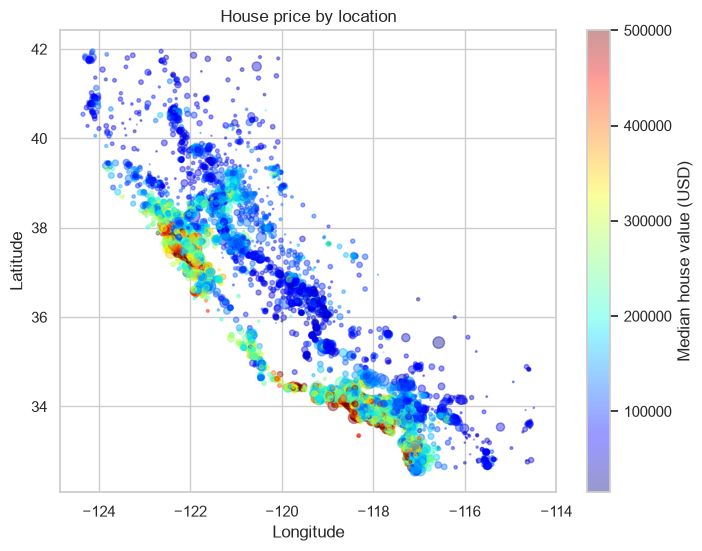

In [11]:
datos = strat_train_set.copy()

plt.figure(figsize=(8, 6))
sc = plt.scatter(datos["longitude"], datos["latitude"],
                 s=datos["population"] / 100, alpha=0.4,
                 c=datos["median_house_value"], cmap="jet")
plt.colorbar(sc, label="Median house value (USD)")
plt.xlabel("Longitude"); plt.ylabel("Latitude")
plt.title("House price by location")
plt.show()

### 4.3 Correlations

In [12]:
corr = datos.corr(numeric_only=True)
corr["median_house_value"].sort_values(ascending=False)

median_house_value    1.000000
median_income         0.688380
total_rooms           0.137455
housing_median_age    0.102175
households            0.071426
total_bedrooms        0.054635
population           -0.020153
longitude            -0.050859
latitude             -0.139584
Name: median_house_value, dtype: float64

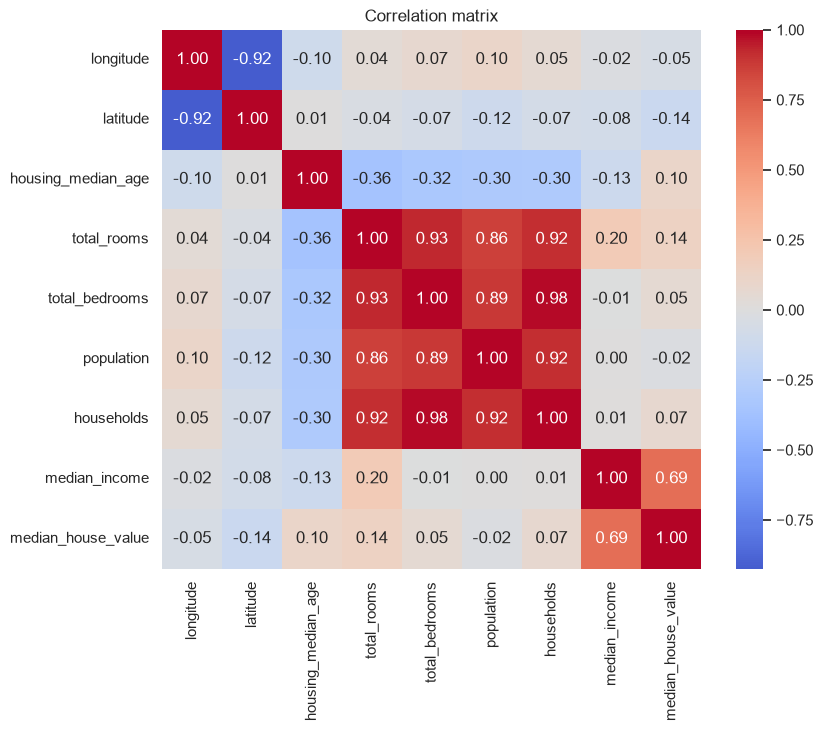

In [13]:
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation matrix")
plt.show()

### 4.4 Scatter plots

The median income is the variable most correlated with the house value.

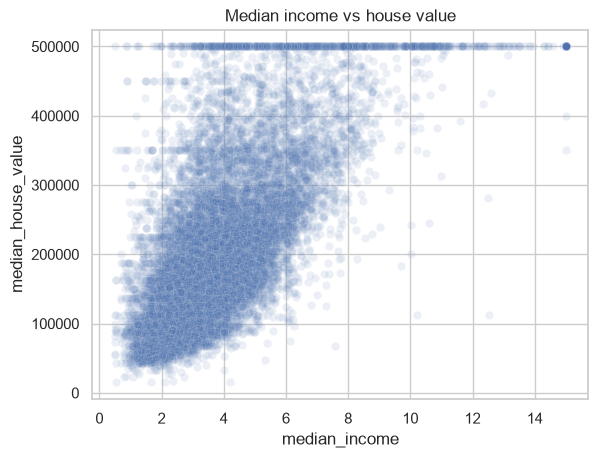

In [14]:
sns.scatterplot(data=datos, x="median_income", y="median_house_value",
                alpha=0.1, color="#4C72B0")
plt.title("Median income vs house value")
plt.show()

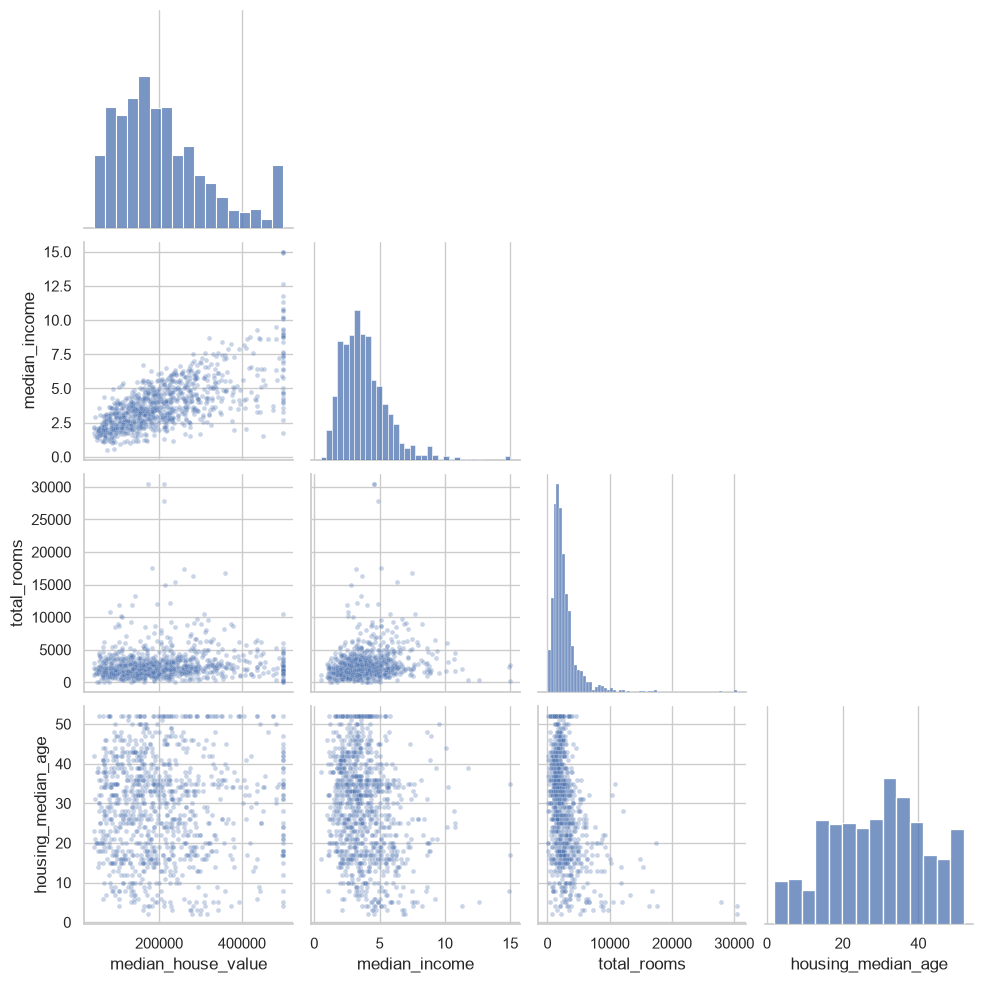

In [15]:
atributos = ["median_house_value", "median_income", "total_rooms", "housing_median_age"]
sns.pairplot(datos[atributos].sample(1000, random_state=42), corner=True,
             plot_kws={"alpha": 0.3, "s": 12})
plt.show()

### 4.5 Combined attributes

Combining attributes improves the correlation: `bedrooms_ratio` is more informative.

In [16]:
datos["rooms_per_house"] = datos["total_rooms"] / datos["households"]
datos["bedrooms_ratio"] = datos["total_bedrooms"] / datos["total_rooms"]
datos["people_per_house"] = datos["population"] / datos["households"]

datos.corr(numeric_only=True)["median_house_value"].sort_values(ascending=False)

median_house_value    1.000000
median_income         0.688380
rooms_per_house       0.143663
total_rooms           0.137455
housing_median_age    0.102175
households            0.071426
total_bedrooms        0.054635
population           -0.020153
people_per_house     -0.038224
longitude            -0.050859
latitude             -0.139584
bedrooms_ratio       -0.256397
Name: median_house_value, dtype: float64

### 4.6 Separating predictors and target

In [17]:
housing = strat_train_set.drop("median_house_value", axis=1)
housing_labels = strat_train_set["median_house_value"].copy()

### 4.7 Log transformation

Several variables are skewed to the right; the logarithm makes their
distribution more symmetric.

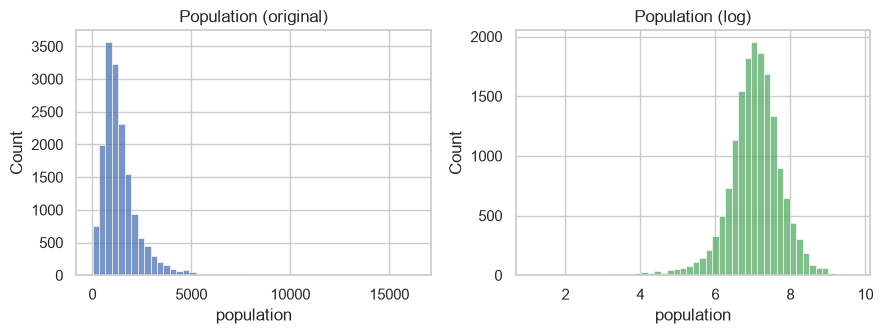

In [18]:
fig, axs = plt.subplots(1, 2, figsize=(9, 3.5))
sns.histplot(housing["population"], bins=50, ax=axs[0], color="#4C72B0")
axs[0].set_title("Population (original)")
sns.histplot(np.log(housing["population"]), bins=50, ax=axs[1], color="#55A868")
axs[1].set_title("Population (log)")
plt.tight_layout()
plt.show()

### 4.8 Imputation, anomalies, categorical variables and normalisation (pipeline)

We build a `ColumnTransformer` with all the preprocessing:
imputation of missing values with the median, ratios between attributes,
log transformation, *one-hot* encoding of the categorical variable and
standardisation.

In [19]:
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer, make_column_selector

def column_ratio(X):
    return X[:, [0]] / X[:, [1]]

def ratio_name(function_transformer, feature_names_in):
    return ["ratio"]

def ratio_pipeline():
    return make_pipeline(
        SimpleImputer(strategy="median"),
        FunctionTransformer(column_ratio, feature_names_out=ratio_name),
        StandardScaler())

log_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    FunctionTransformer(np.log, feature_names_out="one-to-one"),
    StandardScaler())

cat_pipeline = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore"))

default_num_pipeline = make_pipeline(SimpleImputer(strategy="median"),
                                     StandardScaler())

preprocessing = ColumnTransformer([
    ("bedrooms", ratio_pipeline(), ["total_bedrooms", "total_rooms"]),
    ("rooms_per_house", ratio_pipeline(), ["total_rooms", "households"]),
    ("people_per_house", ratio_pipeline(), ["population", "households"]),
    ("log", log_pipeline, ["total_bedrooms", "total_rooms", "population",
                           "households", "median_income"]),
    ("cat", cat_pipeline, make_column_selector(dtype_include=object)),
], remainder=default_num_pipeline)

In [20]:
housing_prepared = preprocessing.fit_transform(housing)
print("Shape after preprocessing:", housing_prepared.shape)

Shape after preprocessing: (16512, 16)


**Treatment of anomalies (optional).** We can detect outliers
with `IsolationForest` and remove them before training.

In [21]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(random_state=42)
outliers = iso.fit_predict(preprocessing.transform(housing))
print("Anomalies detected:", int((outliers == -1).sum()))

Anomalies detected: 2104


## Part 5. Linear regression and predictions

In [22]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

lin_reg = make_pipeline(preprocessing, LinearRegression())
lin_reg.fit(housing, housing_labels)

predicciones = lin_reg.predict(housing)
lin_rmse = np.sqrt(mean_squared_error(housing_labels, predicciones))
print("Train RMSE (linear regression): {:,.0f}".format(lin_rmse))

Train RMSE (linear regression): 70,630


In [23]:
comparacion = pd.DataFrame({
    "Predicted": predicciones[:5].round(-2),
    "Actual": housing_labels.iloc[:5].values})
comparacion

,Predicted,Actual
0,260100.0,458300.0
1,357900.0,483800.0
2,125800.0,101700.0
3,110000.0,96100.0
4,298900.0,361800.0


In [24]:
from sklearn.model_selection import cross_val_score

lin_rmses = -cross_val_score(lin_reg, housing, housing_labels,
                             scoring="neg_root_mean_squared_error", cv=10)
print("Cross-validation RMSE: {:,.0f} (+/- {:,.0f})".format(
    lin_rmses.mean(), lin_rmses.std()))

Cross-validation RMSE: 71,791 (+/- 3,782)


We also compare a decision tree and a random forest with
cross-validation. The random forest is clearly the best.

In [25]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

tree_reg = make_pipeline(preprocessing, DecisionTreeRegressor(random_state=42))
tree_rmses = -cross_val_score(tree_reg, housing, housing_labels,
                              scoring="neg_root_mean_squared_error", cv=10)

forest_reg = make_pipeline(preprocessing,
                           RandomForestRegressor(random_state=42))
forest_rmses = -cross_val_score(forest_reg, housing, housing_labels,
                                scoring="neg_root_mean_squared_error", cv=10)

pd.DataFrame({
    "Model": ["Linear regression", "Decision tree", "Random forest"],
    "RMSE (CV)": [lin_rmses.mean(), tree_rmses.mean(), forest_rmses.mean()]
}).round(0)

,Model,RMSE (CV)
0,Linear regression,71791.0
1,Decision tree,70043.0
2,Random forest,49632.0


## Part 6. Hyperparameter tuning with GridSearch

In [26]:
from sklearn.model_selection import GridSearchCV

full_pipeline = Pipeline([
    ("preprocessing", preprocessing),
    ("random_forest", RandomForestRegressor(random_state=42)),
])

param_grid = [{
    "random_forest__max_features": [4, 6, 8],
    "random_forest__n_estimators": [100, 150],
}]

grid_search = GridSearchCV(full_pipeline, param_grid, cv=3,
                           scoring="neg_root_mean_squared_error")
grid_search.fit(housing, housing_labels)

print("Best hyperparameters:", grid_search.best_params_)
print("Best RMSE (CV): {:,.0f}".format(-grid_search.best_score_))

Best hyperparameters: {'random_forest__max_features': 6, 'random_forest__n_estimators': 150}
Best RMSE (CV): 49,381


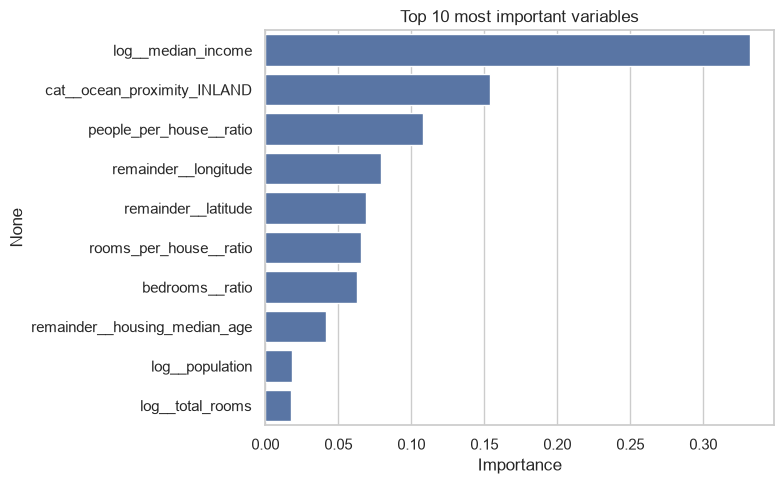

In [27]:
final_model = grid_search.best_estimator_
importancias = final_model["random_forest"].feature_importances_
nombres = final_model["preprocessing"].get_feature_names_out()

imp = pd.Series(importancias, index=nombres).sort_values(ascending=False).head(10)
plt.figure(figsize=(8, 5))
sns.barplot(x=imp.values, y=imp.index, color="#4C72B0")
plt.title("Top 10 most important variables"); plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## Part 7. Complete pipeline and final evaluation

The whole flow (preprocessing + model) is in one `Pipeline`,
so the same transformations are applied automatically to new data.
We evaluate it on the test set.

In [28]:
X_test = strat_test_set.drop("median_house_value", axis=1)
y_test = strat_test_set["median_house_value"].copy()

final_predictions = final_model.predict(X_test)
final_rmse = np.sqrt(mean_squared_error(y_test, final_predictions))
print("RMSE on the test set: {:,.0f}".format(final_rmse))

RMSE on the test set: 48,861


In [29]:
from scipy import stats

confidence = 0.95
errores2 = (final_predictions - y_test) ** 2
ic = np.sqrt(stats.t.interval(confidence, len(errores2) - 1,
                              loc=errores2.mean(), scale=stats.sem(errores2)))
print("95% confidence interval of the RMSE: [{:,.0f} ; {:,.0f}]".format(ic[0], ic[1]))

95% confidence interval of the RMSE: [46,548 ; 51,070]


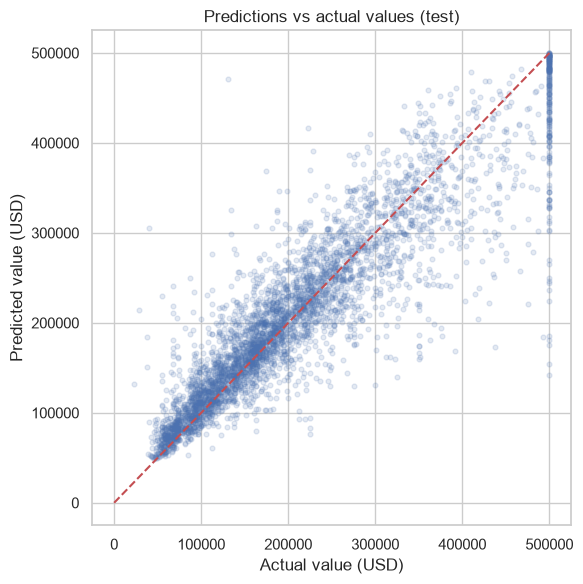

In [30]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, final_predictions, alpha=0.15, color="#4C72B0", s=12)
plt.plot([0, 500001], [0, 500001], "r--", lw=1.5)
plt.xlabel("Actual value (USD)"); plt.ylabel("Predicted value (USD)")
plt.title("Predictions vs actual values (test)")
plt.tight_layout()
plt.show()

In [31]:
import joblib

joblib.dump(final_model, "california_housing_model.pkl")
print("Model saved in california_housing_model.pkl")

Model saved in california_housing_model.pkl


## Conclusions

- The **median income** is the most important predictor of the house value,
  followed by the location and the `INLAND` category.
- The preprocessing (imputation, ratios, log transformation, encoding and
  standardisation) is integrated in one reproducible *pipeline*.
- The **random forest** tuned with `GridSearch` is much better than the
  linear regression and the decision tree.
- The final model reaches an **RMSE of around 49.000 USD** on the test set.